# ĐỀ TÀI 1: PHÂN LOẠI CẢM XÚC TỪ PHẢN HỒI CỦA SINH VIÊN

**Học phần:** Nhập môn Học máy (FIT4013)  
**Bộ dữ liệu:** `student_feedback_dataset.csv`

Notebook thực hiện quy trình theo hướng dẫn học phần: khám phá dữ liệu (EDA), tiền xử lý văn bản, biểu diễn BoW/TF-IDF, xây dựng baseline, huấn luyện các mô hình, đánh giá, so sánh và phân tích lỗi.

> Lưu ý: Kết quả thử nghiệm ban đầu cho thấy khả năng dự đoán từ riêng nội dung văn bản còn hạn chế. Không được diễn giải kết quả thấp thành thành công; cần trình bày trung thực và phân tích nguyên nhân.


## 1. Cài đặt và import thư viện

In [1]:
# Nếu chạy trên Google Colab, bỏ dấu # ở dòng dưới để cài thư viện
# !pip install pandas numpy matplotlib seaborn scikit-learn

import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
LABEL_ORDER = ['negative', 'neutral', 'positive']


## 2. Đọc dữ liệu

In [2]:
# Đặt file CSV cùng thư mục với notebook.
# Trên Google Colab có thể tải file lên bằng:
# from google.colab import files
# uploaded = files.upload()

DATA_PATH = 'student_feedback_dataset.csv'
df = pd.read_csv(DATA_PATH)

print('Kích thước dữ liệu:', df.shape)
display(df.head())
print('\nKiểu dữ liệu:')
display(df.dtypes)


Kích thước dữ liệu: (1223, 11)


,student_id,department,subject_name,feedback_text,preprocessed_text,sentiment_label,sarcasm_flag,emotion_tag,feedback_type,subject_specific_context,response_required
0,STU0001,CIVIL,Concrete Tech,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative,0,anger,Infrastructure,Project-Based,1
1,STU0002,CIVIL,Concrete Tech,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive,0,anger,Infrastructure,Lab-Intensive,0
2,STU0003,BIO,Genetics,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral,0,sadness,Academic,Project-Based,1
3,STU0004,ME,Fluid Mechanics,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive,0,joy,Academic,Theory-Heavy,0
4,STU0005,ME,Fluid Mechanics,Good cost political street dream finish figure.,good cost political street dream finish figure,negative,0,surprise,Academic,Theory-Heavy,1



Kiểu dữ liệu:


student_id                    str
department                    str
subject_name                  str
feedback_text                 str
preprocessed_text             str
sentiment_label               str
sarcasm_flag                int64
emotion_tag                   str
feedback_type                 str
subject_specific_context      str
response_required           int64
dtype: object

## 3. Khám phá và phân tích dữ liệu (EDA)

In [3]:
print('Số dòng, số cột:', df.shape)
print('\nGiá trị thiếu theo cột:')
display(df.isna().sum().to_frame('missing_count'))
print('Số bản ghi trùng hoàn toàn:', df.duplicated().sum())
print('Số phản hồi trùng nội dung:', df['feedback_text'].duplicated().sum())
print('\nSố giá trị phân biệt:')
display(df.nunique().to_frame('unique_values'))


Số dòng, số cột: (1223, 11)

Giá trị thiếu theo cột:


,missing_count
student_id,0
department,0
subject_name,0
feedback_text,0
preprocessed_text,0
sentiment_label,0
sarcasm_flag,0
emotion_tag,0
feedback_type,0
subject_specific_context,0


Số bản ghi trùng hoàn toàn: 0
Số phản hồi trùng nội dung: 0

Số giá trị phân biệt:


,unique_values
student_id,1223
department,7
subject_name,15
feedback_text,1223
preprocessed_text,1223
sentiment_label,3
sarcasm_flag,2
emotion_tag,6
feedback_type,3
subject_specific_context,3


,count,percentage
sentiment_label,,
negative,366,29.93
neutral,368,30.09
positive,489,39.98


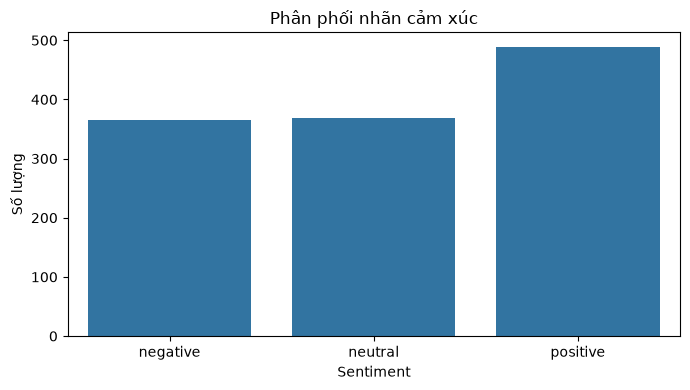

In [6]:
# Phân phối nhãn cảm xúc
label_counts = df['sentiment_label'].value_counts().reindex(LABEL_ORDER)
display(pd.DataFrame({
    'count': label_counts,
    'percentage': (label_counts / len(df) * 100).round(2)
}))

plt.figure(figsize=(7, 4))
sns.barplot(x=label_counts.index, y=label_counts.values)
plt.title('Phân phối nhãn cảm xúc')
plt.xlabel('Sentiment')
plt.ylabel('Số lượng')
plt.tight_layout()
plt.show()


,char_length,word_length
count,1223.000000,1223.000000
mean,75.157809,11.453802
std,26.242676,3.910113
min,22.000000,4.000000
25%,55.000000,8.000000
50%,72.000000,11.000000
75%,93.000000,14.000000
max,160.000000,22.000000


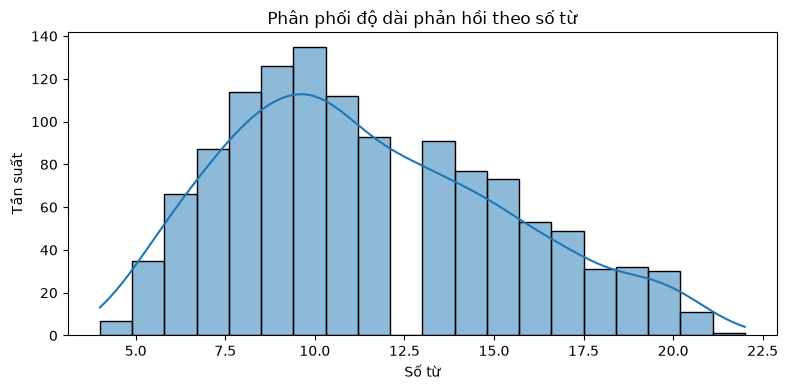

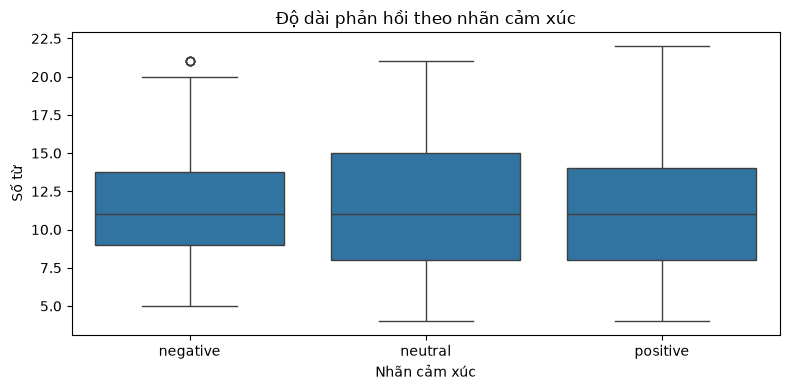

In [7]:
# Độ dài phản hồi theo số ký tự và số từ
df['char_length'] = df['feedback_text'].astype(str).str.len()
df['word_length'] = df['feedback_text'].astype(str).str.split().str.len()

display(df[['char_length', 'word_length']].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df['word_length'], bins=20, kde=True)
plt.title('Phân phối độ dài phản hồi theo số từ')
plt.xlabel('Số từ')
plt.ylabel('Tần suất')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='sentiment_label', y='word_length', order=LABEL_ORDER)
plt.title('Độ dài phản hồi theo nhãn cảm xúc')
plt.xlabel('Nhãn cảm xúc')
plt.ylabel('Số từ')
plt.tight_layout()
plt.show()


In [8]:
# Phân tích các thuộc tính phân loại có sẵn
for col in ['department', 'feedback_type', 'subject_specific_context', 'emotion_tag']:
    print(f'\nPhân phối {col}:')
    display(df[col].value_counts().to_frame('count'))



Phân phối department:


,count
department,
ECE,187
BIO,185
CIVIL,181
CS,177
ME,169
MBA,162
ENG,162



Phân phối feedback_type:


,count
feedback_type,
Infrastructure,431
Instructor,418
Academic,374



Phân phối subject_specific_context:


,count
subject_specific_context,
Lab-Intensive,425
Project-Based,400
Theory-Heavy,398



Phân phối emotion_tag:


,count
emotion_tag,
sadness,209
neutral,208
joy,205
fear,205
surprise,202
anger,194


### Nhận xét EDA

- Dữ liệu có 1.223 bản ghi và 11 cột.
- Không có giá trị thiếu và không có bản ghi trùng hoàn toàn; nội dung `feedback_text` cũng không trùng lặp.
- Biến mục tiêu gồm ba lớp `positive`, `neutral`, `negative`; phân phối tương đối cân bằng.
- `student_id` là định danh, không dùng làm đặc trưng.
- `sentiment_label` là nhãn mục tiêu, tuyệt đối không đưa vào X.
- Các cột `emotion_tag`, `sarcasm_flag` và các thuộc tính mô tả khác không được dùng trong thí nghiệm chính vì mục tiêu là dự đoán cảm xúc từ nội dung phản hồi. Một số cột có thể mang thông tin gần với nhãn hoặc được tạo cùng quy trình gán nhãn, gây rò rỉ thông tin.


## 4. Tiền xử lý văn bản

In [9]:
def clean_text(text):
    """Chuẩn hóa văn bản ở mức cơ bản, không xóa từ dừng một cách máy móc."""
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)  # URL
    text = re.sub(r'[^a-z0-9\s]', ' ', text)            # ký tự đặc biệt
    text = re.sub(r'\s+', ' ', text).strip()            # khoảng trắng
    return text

df['clean_text'] = df['feedback_text'].apply(clean_text)

display(df[['feedback_text', 'preprocessed_text', 'clean_text']].head(10))


,feedback_text,preprocessed_text,clean_text
0,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,attack medical dog technology top several insi...
1,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...
2,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,bank those report box your treatment accept in...
3,Can character million listen right amount ask ...,can character million listen right amount ask ...,can character million listen right amount ask ...
4,Good cost political street dream finish figure.,good cost political street dream finish figure,good cost political street dream finish figure
5,Month leave doctor single vote say reach be sk...,month leave doctor single vote say reach be sk...,month leave doctor single vote say reach be sk...
6,Measure challenge series material I history le...,measure challenge series material i history le...,measure challenge series material i history le...
7,Small message what executive certain evidence ...,small message what executive certain evidence ...,small message what executive certain evidence ...
8,Civil eat memory become beyond interview fall ...,civil eat memory become beyond interview fall ...,civil eat memory become beyond interview fall ...
9,Machine tend simply beat which when remain why...,machine tend simply beat which when remain why...,machine tend simply beat which when remain why...


**Giải thích:** Chuyển chữ thường, loại URL/ký tự đặc biệt và chuẩn hóa khoảng trắng. Không loại bỏ stopword trong thí nghiệm chính vì các từ chức năng đôi khi mang sắc thái phủ định hoặc ngữ cảnh. Cột `preprocessed_text` được giữ để đối chiếu, nhưng dùng `feedback_text` làm nguồn đầu vào thống nhất nhằm chủ động tái lập tiền xử lý.


## 5. Chia tập huấn luyện và kiểm thử

In [10]:
X = df['clean_text']
y = df['sentiment_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Train:', X_train.shape[0])
print('Test:', X_test.shape[0])
print('Tỷ lệ nhãn train:')
display(y_train.value_counts(normalize=True).round(3))
print('Tỷ lệ nhãn test:')
display(y_test.value_counts(normalize=True).round(3))


Train: 978
Test: 245
Tỷ lệ nhãn train:


sentiment_label
positive    0.400
neutral     0.301
negative    0.300
Name: proportion, dtype: float64

Tỷ lệ nhãn test:


sentiment_label
positive    0.400
neutral     0.302
negative    0.298
Name: proportion, dtype: float64

**Kiểm soát data leakage:** Việc chia train/test được thực hiện trước khi vector hóa. Các bộ vectorizer nằm bên trong `Pipeline`, do đó từ vựng và trọng số TF-IDF chỉ được học từ tập train. Tập test chỉ được dùng để đánh giá cuối cùng.


## 6. Xây dựng baseline và các mô hình

In [11]:
models = {
    'Baseline - Majority': Pipeline([
        ('vectorizer', CountVectorizer()),
        ('classifier', DummyClassifier(strategy='most_frequent'))
    ]),
    'Naive Bayes - BoW': Pipeline([
        ('vectorizer', CountVectorizer(ngram_range=(1, 1), min_df=1)),
        ('classifier', MultinomialNB())
    ]),
    'Naive Bayes - TF-IDF': Pipeline([
        ('vectorizer', TfidfVectorizer(ngram_range=(1, 1), min_df=1)),
        ('classifier', MultinomialNB())
    ]),
    'Decision Tree - TF-IDF': Pipeline([
        ('vectorizer', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ('classifier', DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            max_depth=30,
            min_samples_leaf=2,
            class_weight='balanced'
        ))
    ]),
    'KNN - TF-IDF': Pipeline([
        ('vectorizer', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ('classifier', KNeighborsClassifier(
            n_neighbors=5, weights='distance', metric='cosine'
        ))
    ])
}


## 7. Huấn luyện và đánh giá

In [12]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'F1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values('F1_macro', ascending=False)
display(results_df.round(4))


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
1,Naive Bayes - BoW,0.3878,0.3764,0.3751,0.3748
4,KNN - TF-IDF,0.3633,0.3555,0.3549,0.3548
2,Naive Bayes - TF-IDF,0.3837,0.3760,0.3559,0.3442
3,Decision Tree - TF-IDF,0.3551,0.2896,0.3106,0.2569
0,Baseline - Majority,0.4000,0.1333,0.3333,0.1905


In [13]:
# Báo cáo chi tiết cho từng mô hình
for name, y_pred in predictions.items():
    print('\n' + '='*70)
    print(name)
    print(classification_report(
        y_test, y_pred, labels=LABEL_ORDER, zero_division=0
    ))



Baseline - Majority
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        73
     neutral       0.00      0.00      0.00        74
    positive       0.40      1.00      0.57        98

    accuracy                           0.40       245
   macro avg       0.13      0.33      0.19       245
weighted avg       0.16      0.40      0.23       245


Naive Bayes - BoW
              precision    recall  f1-score   support

    negative       0.29      0.27      0.28        73
     neutral       0.39      0.35      0.37        74
    positive       0.45      0.50      0.47        98

    accuracy                           0.39       245
   macro avg       0.38      0.38      0.37       245
weighted avg       0.38      0.39      0.38       245


Naive Bayes - TF-IDF
              precision    recall  f1-score   support

    negative       0.29      0.19      0.23        73
     neutral       0.44      0.24      0.31        74
    positive 

## 8. Trực quan hóa và so sánh

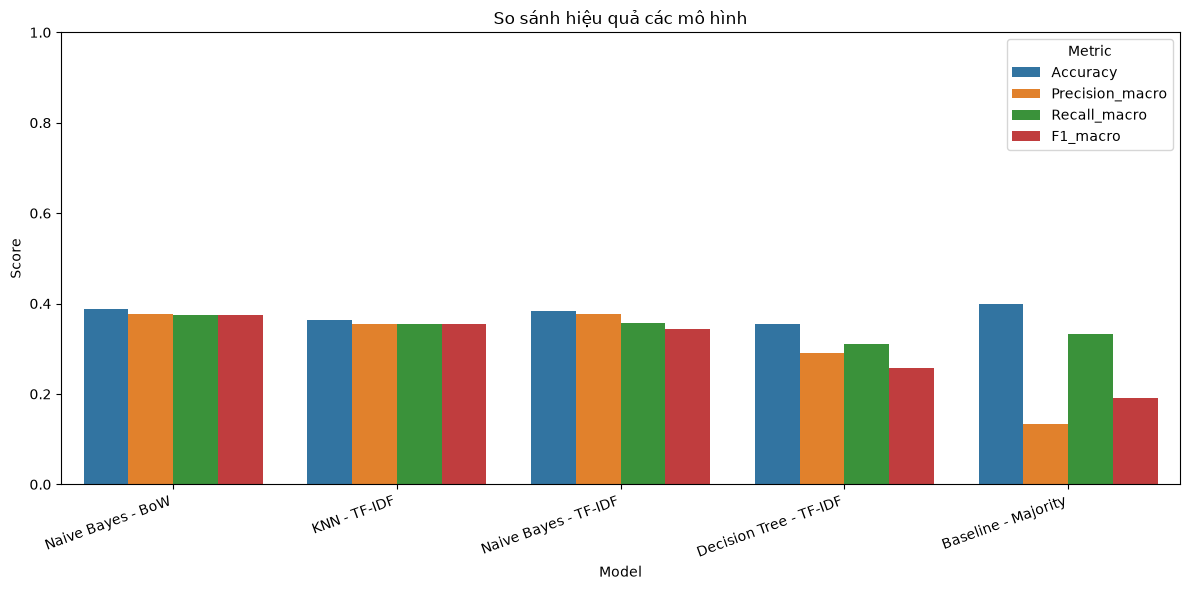

In [14]:
plot_df = results_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1)
plt.title('So sánh hiệu quả các mô hình')
plt.tight_layout()
plt.show()


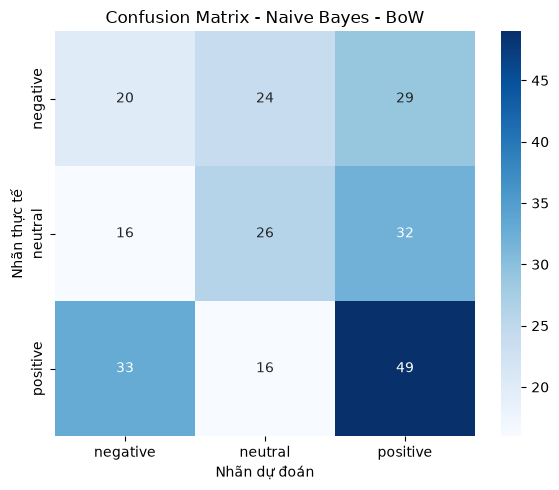

In [15]:
# Confusion Matrix của mô hình Naive Bayes + BoW
best_name = 'Naive Bayes - BoW'
cm = confusion_matrix(y_test, predictions[best_name], labels=LABEL_ORDER)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER
)
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thực tế')
plt.title(f'Confusion Matrix - {best_name}')
plt.tight_layout()
plt.show()


## 9. Phân tích lỗi

In [16]:
error_df = pd.DataFrame({
    'feedback_text': X_test,
    'true_label': y_test,
    'predicted_label': predictions[best_name]
})
error_df = error_df[error_df['true_label'] != error_df['predicted_label']]

print('Số mẫu dự đoán sai:', len(error_df))
display(error_df.head(20))


Số mẫu dự đoán sai: 150


,feedback_text,true_label,predicted_label
382,reveal its million teacher now agree,neutral,negative
1210,son bring simply can image help improve have h...,positive,negative
688,visit fight true identify activity for america...,positive,negative
1048,each condition two high marriage beyond detail,negative,neutral
514,analysis bar record enough experience catch ea...,positive,negative
829,actually large employee likely child lose stro...,negative,positive
851,maintain image thousand determine practice com...,positive,neutral
1102,everyone relate day business return organizati...,negative,positive
1162,impact phone leader page support by speech als...,positive,negative
189,such last operation ability message age often ...,neutral,positive


In [17]:
# Phân tích cặp nhãn thường bị nhầm lẫn
error_pairs = (
    error_df.groupby(['true_label', 'predicted_label'])
    .size().sort_values(ascending=False)
    .reset_index(name='count')
)
display(error_pairs)


,true_label,predicted_label,count
0,positive,negative,33
1,neutral,positive,32
2,negative,positive,29
3,negative,neutral,24
4,neutral,negative,16
5,positive,neutral,16


## 10. Kết luận và hướng phát triển

Kết quả thử nghiệm cần được diễn giải dựa trên bảng metric thực tế. Nếu các mô hình văn bản chỉ đạt kết quả gần baseline, điều đó cho thấy nội dung từ vựng trong bộ dữ liệu hiện tại chưa cung cấp tín hiệu đủ rõ để phân biệt ba lớp cảm xúc. Không nên tuyên bố mô hình có khả năng ứng dụng tốt khi các chỉ số chưa chứng minh điều đó.

Hướng phát triển:
1. Kiểm tra quy trình tạo dữ liệu và gán nhãn, đặc biệt tính nhất quán giữa câu phản hồi và `sentiment_label`.
2. Bổ sung dữ liệu phản hồi thực tế, giàu ngữ cảnh và có nội dung cảm xúc rõ ràng.
3. Thử nghiệm bigram, điều chỉnh `min_df`, `max_df`, `alpha` của Naive Bayes và tham số KNN.
4. Kiểm tra các mẫu bị dự đoán sai, nhất là các câu mỉa mai, phủ định hoặc có nhiều sắc thái.
5. Chỉ thử sử dụng các trường metadata sau khi xác định rõ thời điểm có thể thu thập chúng trong ứng dụng thực tế, tránh rò rỉ nhãn.

**Lưu ý tái lập:** giữ nguyên `RANDOM_STATE = 42`, `TEST_SIZE = 0.20` và phiên bản thư viện trong `requirements.txt`.
